# Step 1 - Select the cells to modify

Moisture-source region of Mongolia's **FRONT** zone (cumulative source `source_cdf` <= 50 %, from `Mongolia/data/mongolia_overlay.nc`),
minus water bodies and minus Mongolia's DES zone (desertified fraction >= 0.75), mapped onto the MATSIRO T42 grid (128 x 64).

A T42 cell is selected if >= 50 % of its area lies in that region and it is land in the model (`gridx01 > 0`).
T42 cells that also contain DES cells are dropped, so the DES zone is never touched.

**Outputs**
- `Code/build_forest_experiment/source_region_T42.npz` - boolean mask of the selected cells (`selected`) and of the dropped ones (`excluded_has_DES`)
- `Figure/build_forest_experiment/source_region_check.png` - figure of the region

Run order: this notebook -> `2_make_forest_files_and_compare.ipynb`.

In [1]:
import json
import numpy as np, xarray as xr
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

from pathlib import Path
HERE = Path.cwd().resolve()        # this notebook's folder: MATSIRO6_IC_exp/Code/build_forest_experiment
BASE = HERE.parents[1]             # MATSIRO6_IC_exp
EXP  = BASE / "Forest_IC_files"   # the 7 experiment .nc files are written here
FIG  = BASE / "Figure" / HERE.name   # figures are written to Figure/<this experiment folder>/
ROOT = HERE.parents[2]             # Geography/  (contains Mongolia/ and Boundary condition/)
SRC  = ROOT / "Boundary condition" / "bc_for_Wei" / "data" / "netcdf"    # original input files
FIG.mkdir(parents=True, exist_ok=True); EXP.mkdir(exist_ok=True)
print("experiment files:", EXP)

experiment files: /Users/peterchang/Projects/Geography/MATSIRO6_IC_exp/Forest_IC_files


## 0 - Settings and input data

In [2]:
LEVEL = 50.0          # cumulative source <= LEVEL % defines the source region
FRAC_MIN = 0.5        # a T42 cell is selected if at least this share of its area is in the region

m = xr.open_dataset(ROOT / "Mongolia" / "data" / "mongolia_overlay.nc")
ZONE = "FRONT"
zones = [str(z) for z in m["zone"].values]
cdf = m.source_cdf.values[zones.index(ZONE)]
lat = m.latitude.values; lon = m.longitude.values % 360
area = m.cell_area.values.astype("float64")
region_all = np.isfinite(cdf) & (cdf <= LEVEL)

# remove water bodies (sea, Caspian Sea, ...): only land counts as source region
import regionmask
land_mask = regionmask.defined_regions.natural_earth_v5_0_0.land_50.mask(m["longitude"].values, m["latitude"].values)
is_land = np.asarray(land_mask == 0)
des_zone = (m.zone_id.values == 1)                 # Mongolia's DES zone: must not be modified
region = region_all & is_land & ~des_zone
print("FRONT source region, 0.25 deg cells:", int(region_all.sum()))
print("  water removed: %d, DES removed: %d -> %d cells remain" %
      ((region_all & ~is_land).sum(), (region_all & des_zone).sum(), region.sum()))

t = xr.open_dataset(SRC / "gridx01.nc", decode_times=False)
g1 = t.GRIDX01[0].values; tlat = t.lat.values; tlon = t.lon.values
latb = np.sort(t.lat_bnds.values, axis=1)

/var/folders/jw/s5f92lzn04z4myhp88qd67h40000gn/T/ipykernel_47626/4195050979.py:14: UserWarning: `land_50` of `natural_earth_v4_1_0` and `natural_earth_v5_0_0` does not quite extend to 90°S - it's recommended to use `natural_earth_v5_1_2` instead. See https://github.com/regionmask/regionmask/issues/487
  land_mask = regionmask.defined_regions.natural_earth_v5_0_0.land_50.mask(m["longitude"].values, m["latitude"].values)


FRONT source region, 0.25 deg cells: 18362
  water removed: 703, DES removed: 1545 -> 16114 cells remain


## 1 - Map the 0.25 deg cells onto the T42 grid

Each 0.25 deg cell is assigned to a T42 cell by its centre; then the area share inside the region is computed per T42 cell.

In [3]:
lat_idx = np.full(lat.shape, -1)
for j in range(64):
    lat_idx[(lat >= latb[j, 0]) & (lat < latb[j, 1])] = j
lon_idx = ((lon + 1.40625) // 2.8125).astype(int) % 128
J = np.repeat(lat_idx[:, None], lon.size, 1)
I = np.repeat(lon_idx[None, :], lat.size, 0)
ok = J >= 0

tot = np.zeros((64, 128)); inreg = np.zeros((64, 128))
np.add.at(tot, (J[ok], I[ok]), area[ok])
np.add.at(inreg, (J[ok & region], I[ok & region]), area[ok & region])
frac = np.where(tot > 0, inreg / np.where(tot > 0, tot, 1), 0.0)
sel = (frac >= FRAC_MIN) & (g1 > 0)                # land cells only

# a T42 cell is much coarser than the DES zone: drop selected cells that contain any DES cell
des_in = np.zeros((64, 128)); np.add.at(des_in, (J[ok & des_zone], I[ok & des_zone]), 1)
mix = sel & (des_in > 0)
sel_all = sel.copy()
sel = sel_all & ~mix
print("selected:", int(sel_all.sum()), "| containing DES (dropped):", int(mix.sum()), "| to modify:", int(sel.sum()))
np.savez(HERE / "source_region_T42.npz", frac=frac, selected=sel, excluded_has_DES=mix, lat=tlat, lon=tlon)

selected: 123 | containing DES (dropped): 13 | to modify: 110


## 2 - Figure

Plotting helpers are taken from `Mongolia/notebooks/重現與疊圖.ipynb`.

In [4]:
def zi(name):
    return zones.index(name)

def draw_borders(ax):
    try:
        regionmask.defined_regions.natural_earth_v5_0_0.countries_50.plot_regions(
            ax=ax, add_label=False, line_kws=dict(color="0.35", lw=0.35))
    except Exception as e:
        print("no global borders:", type(e).__name__)
    with open(ROOT / "Mongolia" / "data" / "mongolia_border.geojson") as f:
        gj = json.load(f)
    for feat in gj["features"]:
        g = feat["geometry"]
        polys = g["coordinates"] if g["type"] == "MultiPolygon" else [g["coordinates"]]
        for poly in polys:
            for ring in poly:
                r = np.asarray(ring)
                ax.plot(r[:, 0], r[:, 1], color="#1E6091", lw=0.9, zorder=5)

def map_axes(ax, extent, step=(10, 5)):
    ax.set_xlim(extent[0], extent[1]); ax.set_ylim(extent[2], extent[3])
    x0, x1 = ax.get_xlim(); y0, y1 = ax.get_ylim()
    ax.set_xticks(np.arange(np.ceil(x0/step[0])*step[0], x1+1, step[0]))
    ax.set_yticks(np.arange(np.ceil(y0/step[1])*step[1], y1+1, step[1]))
    ax.grid(alpha=0.25, lw=0.4, color="0.5", ls=":")
    ax.set_aspect("equal"); ax.set_xlabel("longitude"); ax.set_ylabel("latitude")

/var/folders/jw/s5f92lzn04z4myhp88qd67h40000gn/T/ipykernel_47626/1617278456.py:6: UserWarning: `land_50` of `natural_earth_v4_1_0` and `natural_earth_v5_0_0` does not quite extend to 90°S - it's recommended to use `natural_earth_v5_1_2` instead. See https://github.com/regionmask/regionmask/issues/487
  regionmask.defined_regions.natural_earth_v5_0_0.countries_50.plot_regions(


saved /Users/peterchang/Projects/Geography/MATSIRO6_IC_exp/Figure/source_region_check.png


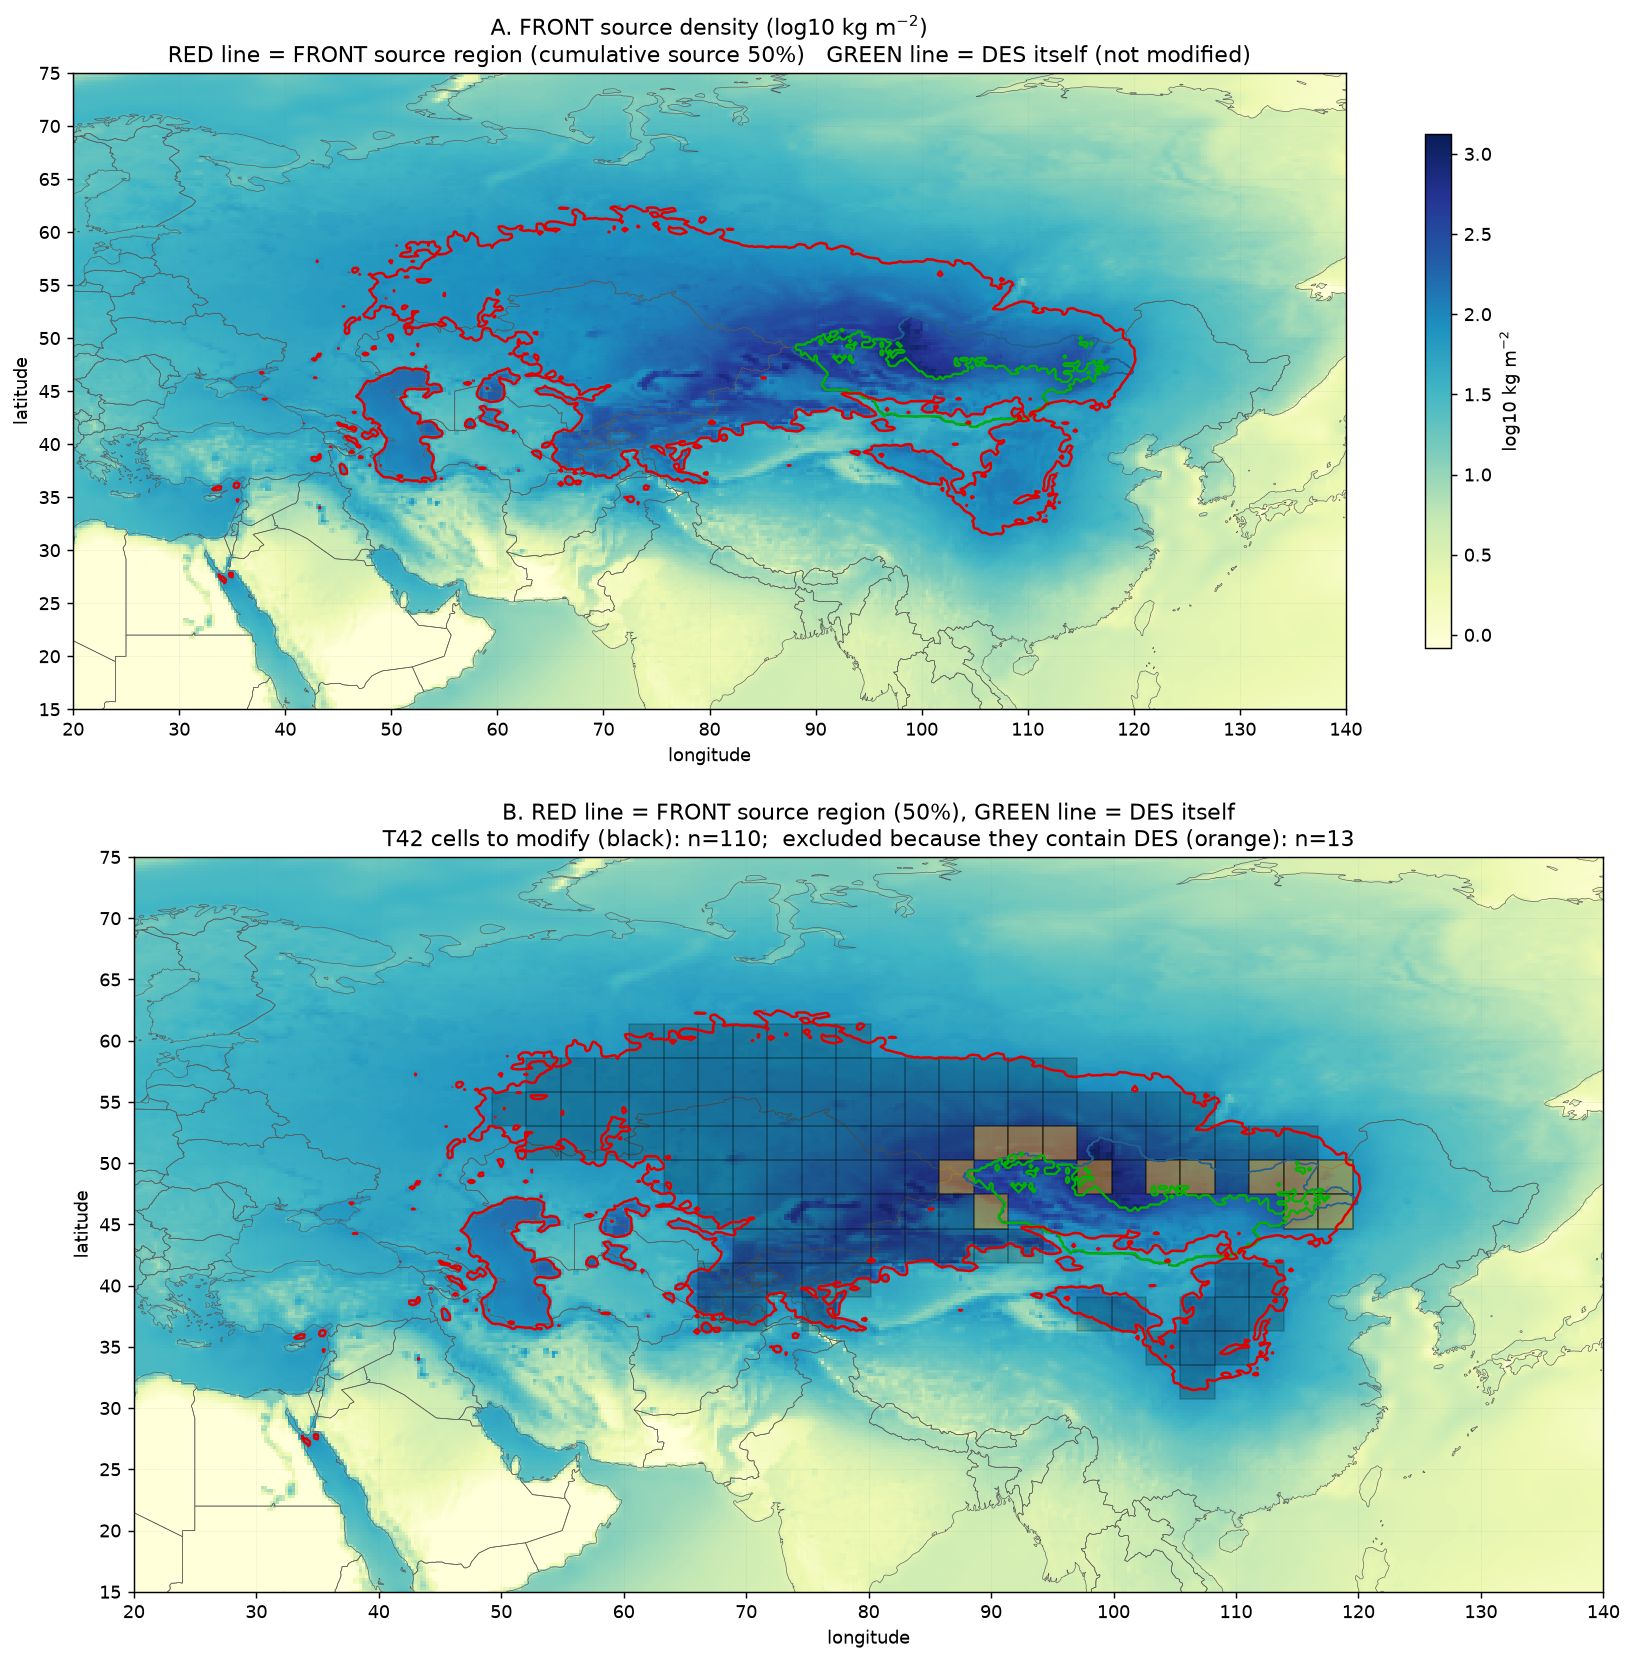

In [5]:
k = zi("FRONT")
dens = m["e_track"].values[k]; pos = dens > 0
lon_p = m["longitude"].values
tlon_p = np.where(tlon > 180, tlon - 360, tlon)    # T42 longitude 0..360 -> -180..180
EXTENT = (20, 140, 15, 75)

fig, axes = plt.subplots(2, 1, figsize=(13, 13), dpi=130)
for ax in axes:
    pm = ax.pcolormesh(lon_p, lat, np.log10(np.where(pos, dens, np.nan)), cmap="YlGnBu", shading="auto",
                       vmin=np.log10(np.percentile(dens[pos], 60)), vmax=np.log10(dens[pos].max()))
    ax.contour(lon_p, lat, cdf, levels=[LEVEL], colors=["#e00000"], linewidths=1.4, zorder=7)            # red
    ax.contour(lon_p, lat, des_zone.astype(float), levels=[0.5], colors=["#00b300"], linewidths=1.3, zorder=6)  # green
    draw_borders(ax); map_axes(ax, EXTENT)

axes[0].set_title("A. FRONT source density (log10 kg m$^{-2}$)\nRED line = FRONT source region (cumulative source 50%)   GREEN line = DES itself (not modified)")
plt.colorbar(pm, ax=axes[0], shrink=0.7, label="log10 kg m$^{-2}$")

for j, i in zip(*np.where(sel_all)):
    axes[1].add_patch(Rectangle((tlon_p[i] - 1.40625, latb[j, 0]), 2.8125, latb[j, 1] - latb[j, 0],
                                fill=True, fc=("orange" if mix[j, i] else "k"), alpha=(0.45 if mix[j, i] else 0.18),
                                ec="k", lw=0.9, zorder=4))
axes[1].set_title(f"B. RED line = FRONT source region (50%), GREEN line = DES itself\n"
                  f"T42 cells to modify (black): n={int(sel.sum())};  excluded because they contain DES (orange): n={int(mix.sum())}")
fig.tight_layout(); fig.savefig(FIG / "source_region_check.png", bbox_inches="tight")
print("saved", FIG / "source_region_check.png")